In [56]:
using LinearAlgebra
using PyPlot
using Trapz
using Calculus

In [108]:
function H_spin(
        energies_up::Array{Float64},
        energies_do::Array{Float64},
        thopping::Array{Float64}
        )
    N = length(energies_up)* 2
    Mtrx = zeros(Float64, N,N)
    for i in 1:2:N
        j = Integer((i +1)/2)
        #diagonaleinträge
        Mtrx[i, i] = energies_up[j]
        Mtrx[i+1, i+1] = energies_do[j] # i+1, i and i, i+1 is empty
        if i<N-2
             #rechte Blockmatrix
            Mtrx[i, i+2] = thopping[1]         #11   
            Mtrx[i, i+3] = thopping[2] # 12
            Mtrx[i+1, i+2] = thopping[3]  #21
            Mtrx[i+1, i+3] = thopping[4]  # 22
            #untere Blockmatrix
            Mtrx[i+2, i] = thopping[1]  # oben links 11
            Mtrx[i+3, i] = thopping[2] # unten link 21
            Mtrx[i+2, i+1] = thopping[3] #12
            Mtrx[i+3, i+1] = thopping[4] #22
        end 
    end
    return Matrix(Mtrx)
end 

H_spin (generic function with 3 methods)

In [127]:
energies_up1 = Array(range(0.2, 1, length = 5))
t_hopping1 = Array([0.1 0.1 0.1 0.1]) # for hopping matrix order: ( 11, 12, 21, 22)
H1 = H_spin(energies_up1, energies_up1, t_hopping1*1.5)

10×10 Array{Float64,2}:
 0.2   0.0   0.15  0.15  0.0   0.0   0.0   0.0   0.0   0.0
 0.0   0.2   0.15  0.15  0.0   0.0   0.0   0.0   0.0   0.0
 0.15  0.15  0.4   0.0   0.15  0.15  0.0   0.0   0.0   0.0
 0.15  0.15  0.0   0.4   0.15  0.15  0.0   0.0   0.0   0.0
 0.0   0.0   0.15  0.15  0.6   0.0   0.15  0.15  0.0   0.0
 0.0   0.0   0.15  0.15  0.0   0.6   0.15  0.15  0.0   0.0
 0.0   0.0   0.0   0.0   0.15  0.15  0.8   0.0   0.15  0.15
 0.0   0.0   0.0   0.0   0.15  0.15  0.0   0.8   0.15  0.15
 0.0   0.0   0.0   0.0   0.0   0.0   0.15  0.15  1.0   0.0
 0.0   0.0   0.0   0.0   0.0   0.0   0.15  0.15  0.0   1.0

In [119]:
energies_up2 = Array(range(0.2, 1, length= 5))
energies_do2 = Array(range(0.3, 1.1, length = 5))
H2 = H_spin(energies_up2, energies_do2, t_hopping1.*2 )

10×10 Array{Float64,2}:
 0.2  0.0  0.2  0.2  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.3  0.2  0.2  0.0  0.0  0.0  0.0  0.0  0.0
 0.2  0.2  0.4  0.0  0.2  0.2  0.0  0.0  0.0  0.0
 0.2  0.2  0.0  0.5  0.2  0.2  0.0  0.0  0.0  0.0
 0.0  0.0  0.2  0.2  0.6  0.0  0.2  0.2  0.0  0.0
 0.0  0.0  0.2  0.2  0.0  0.7  0.2  0.2  0.0  0.0
 0.0  0.0  0.0  0.0  0.2  0.2  0.8  0.0  0.2  0.2
 0.0  0.0  0.0  0.0  0.2  0.2  0.0  0.9  0.2  0.2
 0.0  0.0  0.0  0.0  0.0  0.0  0.2  0.2  1.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.2  0.2  0.0  1.1

In [129]:
t_hopping2 = Array([0.1 0 0 0.3])
H3 = H_spin(energies_up1, energies_up1, t_hopping2)

10×10 Array{Float64,2}:
 0.2  0.0  0.1  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.2  0.0  0.3  0.0  0.0  0.0  0.0  0.0  0.0
 0.1  0.0  0.4  0.0  0.1  0.0  0.0  0.0  0.0  0.0
 0.0  0.3  0.0  0.4  0.0  0.3  0.0  0.0  0.0  0.0
 0.0  0.0  0.1  0.0  0.6  0.0  0.1  0.0  0.0  0.0
 0.0  0.0  0.0  0.3  0.0  0.6  0.0  0.3  0.0  0.0
 0.0  0.0  0.0  0.0  0.1  0.0  0.8  0.0  0.1  0.0
 0.0  0.0  0.0  0.0  0.0  0.3  0.0  0.8  0.0  0.3
 0.0  0.0  0.0  0.0  0.0  0.0  0.1  0.0  1.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.3  0.0  1.0

In [57]:
function G_und_trans(energy::Float64,
        eta::Float64,
        Hamiltonian::Array{Float64},
        gammas::Array{Float64})
    dim = size(Hamiltonian)[1]
    Matrix_I_e = (energy + eta*1im ) * Matrix(I, dim,dim)

    gamma_l = zeros(Float64, dim,dim)
    gamma_l[1, 1] = gammas[1]
    gamma_l[2,2] = gammas[1]
    # as spin up and spin down sttate of first site are couled to lead? analogue for last of course
    #?!
    gamma_r = zeros(Float64, dim,dim)
    gamma_r[end, end] = gammas[2]
    gamma_r[end-1, end-1] = gammas[2]
    
    matrix_self = -1im *(gamma_l+ gamma_r)/ 2 
    G_ret =  inv(Matrix_I_e - matrix_self - Hamiltonian)
    G_adv = adjoint(G_ret)
    final_Matrix = gamma_l* G_adv * gamma_r * G_ret
    return real.(tr(final_Matrix))
end 

G_und_trans (generic function with 1 method)

[-0.08006093543810078, 0.20000000000000012, 0.28772268079309193, 0.40000000000000047, 0.5999999999999999, 0.5999999999999999, 0.8000000000000005, 0.9122773192069082, 0.9999999999999998, 1.2800609354381025]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


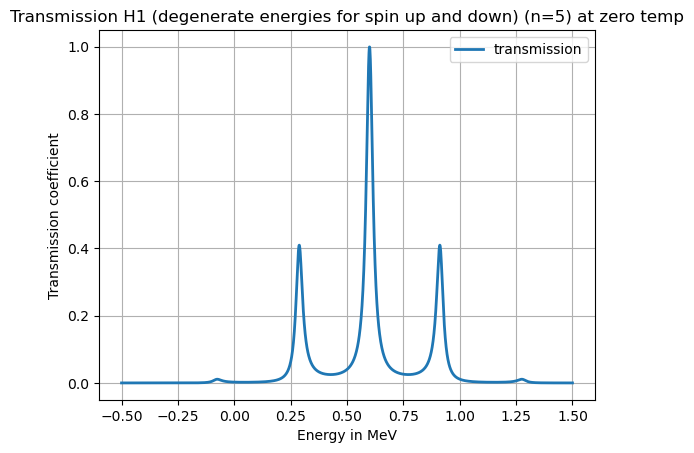

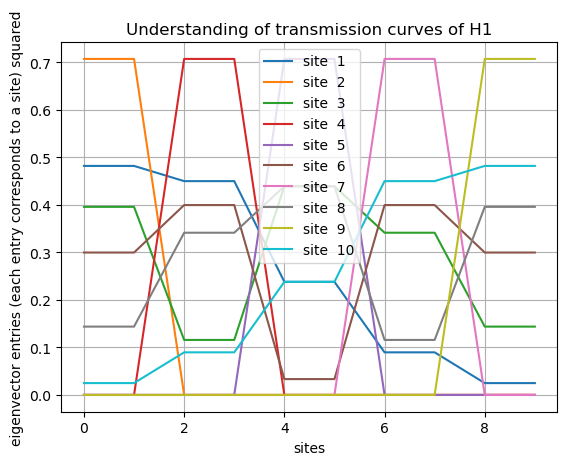

In [128]:

# defining variable for G        
emin, emax = -0.5, 1.5
E_list = Array(range(emin, emax, length = 2000))
eta = 10^(-7)
gammas = Array([.1 .1])

transm_H1 = [G_und_trans(E,eta, H1, gammas) for E in E_list]
plt.figure()
plt.plot(
    E_list, transm_H1,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0, 0.02)
plt.title("Transmission H1 (degenerate energies for spin up and down) (n=5) at zero temp")
plt.xlabel( "Energy in MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_spin_1.pdf")
plt.show()
ei1, vec1 = eigen(H1)
print(ei1)

plt.figure()
for i in range(1, size(vec1)[1], step = 1)
    plt.plot(abs.(vec1[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves of H1")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_spin_H1.pdf")
plt.show()

[-0.17908227068581706, 0.2208450782432676, 0.2761038077591751, 0.44754879608505904, 0.6372019912633972, 0.6627980087366032, 0.8524512039149424, 1.0238961922408256, 1.0791549217567327, 1.4790822706858189]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


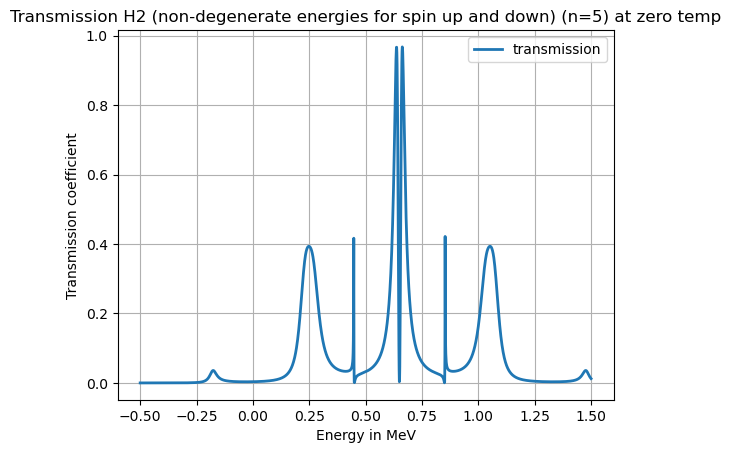

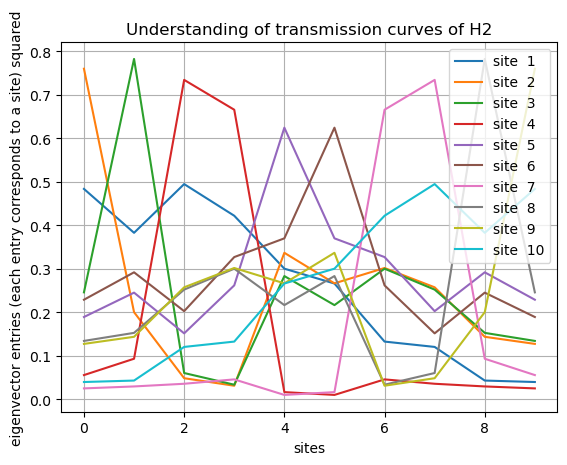

In [120]:
# the same for H2
transm_H2 = [G_und_trans(E,eta, H2, gammas) for E in E_list]
plt.figure()
plt.plot(
    E_list, transm_H2,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0,0.2* 1e-6)
plt.title("Transmission H2 (non-degenerate energies for spin up and down) (n=5) at zero temp")
plt.xlabel( "Energy in MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_spin_2.pdf")
plt.show()
ei2, vec2 = eigen(H2)
print(ei2)

plt.figure()
for i in range(1, size(vec2)[1], step = 1)
    plt.plot(abs.(vec2[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves of H2")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_spin_H2.pdf")
plt.show()

[-0.08006093543810122, 0.15491293350731206, 0.28772268079309216, 0.3953112039193818, 0.5999999999999998, 0.6000000000000001, 0.8046887960806195, 0.9122773192069089, 1.0450870664926875, 1.2800609354381023]

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


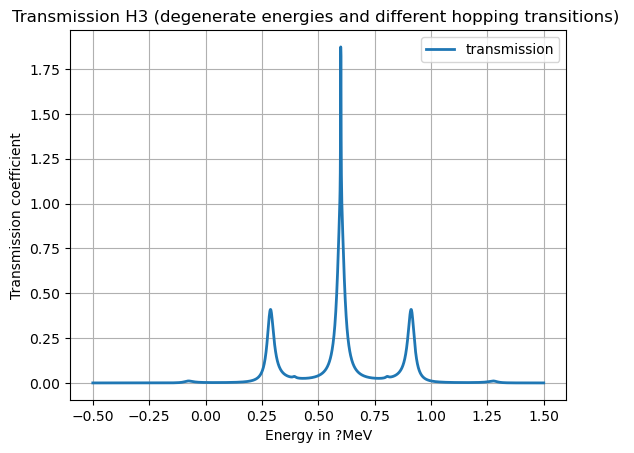

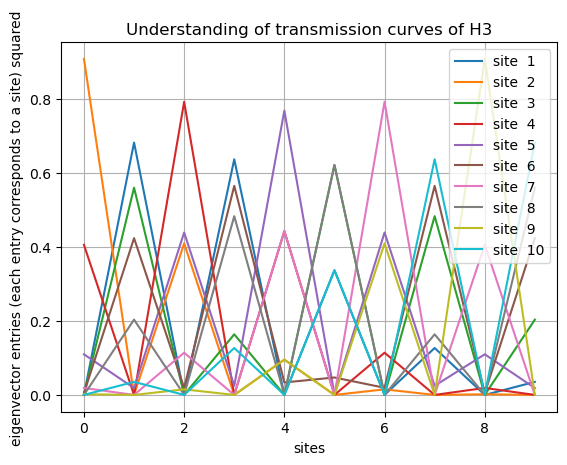

In [130]:
transm_H3 = [G_und_trans(E,eta, H3, gammas) for E in E_list]
plt.figure()
plt.plot(
    E_list, transm_H3,    #mit f. normalerweise komponentenweise
    label = "transmission",
    linewidth = 2 
    )
plt.legend()
#plt.ylim( 0, 0.02)
plt.title("Transmission H3 (degenerate energies and different hopping transitions) ")
plt.xlabel( "Energy in ?MeV")
plt.ylabel( "Transmission coefficient")
plt.grid("true")
plt.savefig("transmission_spin_3.pdf")
plt.show()
ei3, vec3 = eigen(H3)
print(ei3)

plt.figure()
for i in range(1, size(vec3)[1], step = 1)
    plt.plot(abs.(vec3[:,i]), label="site  "*string(i))
end
plt.grid("both")
plt.legend()
plt.title( "Understanding of transmission curves of H3")
plt.ylabel("eigenvector entries (each entry corresponds to a site) squared")
plt.xlabel("sites")
plt.savefig("eigen_vec^2_spin_H3.pdf")
plt.show()

In [92]:
function integral_f(x_data::Array{Float64}, H::Array{Float64},  eta::Float64, gammas::Array{Float64})
    y_int = []
    for i in 1:(length(x_data)-1)
        x_neu  = range(x_data[i], x_data[i+1], length = 10)
        
        y_neu = [G_und_trans(x/ 2,eta, H, gammas) for x in x_neu]
        if i ==1
            push!(y_int, trapz(x_neu, y_neu))
        end
        if i > 1
            s = y_int[i-1] +  trapz(x_neu, y_neu)
            push!(y_int, s)
        end
    end
        plt.plot(x_data[1:end-1], y_int, label= "current")
       
    return y_int
end

integral_f (generic function with 1 method)

sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.
sys:1: UserWarning: Matplotlib is currently using agg, which is a non-GUI backend, so cannot show the figure.


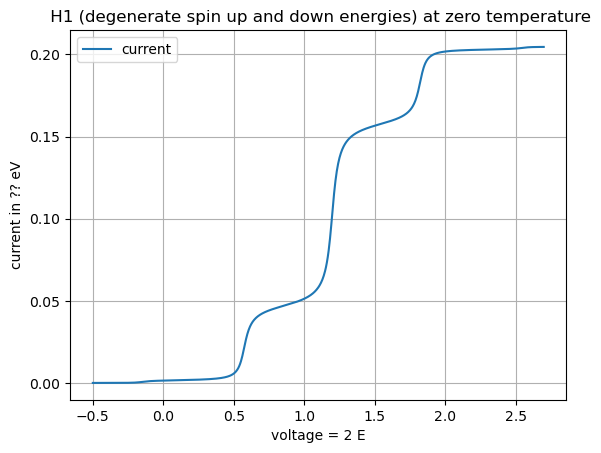

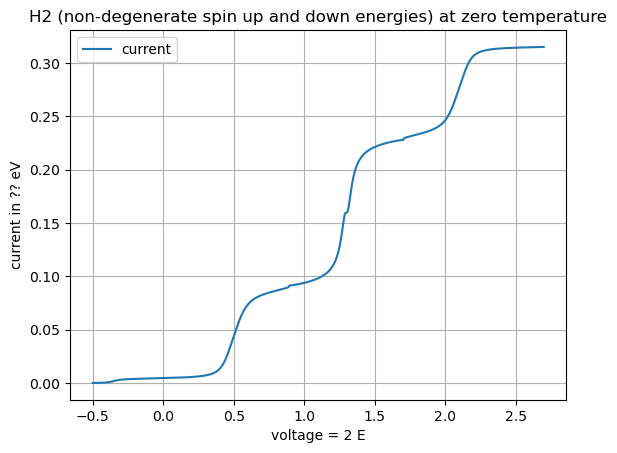

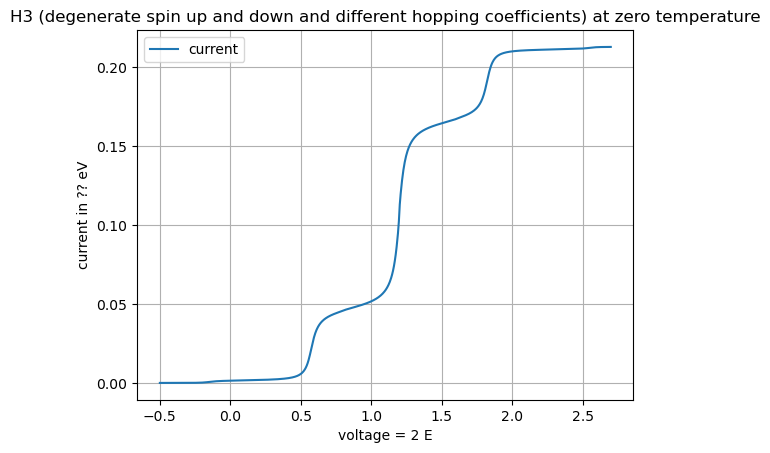

In [131]:
u_list= Array(range(-0.5,2.7, length = 1000))
plt.figure( )
integral_f(u_list, H1,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( " H1 (degenerate spin up and down energies) at zero temperature")
plt.savefig("current_spin_H1.pdf")
plt.show()


plt.figure( )
integral_f(u_list, H2,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( "H2 (non-degenerate spin up and down energies) at zero temperature")
plt.savefig("current_spin_H2.pdf")
plt.show()

plt.figure( )
integral_f(u_list, H3,  eta, gammas)
plt.grid( "true")
plt.legend()
plt.xlabel( "voltage = 2 E")
plt.ylabel( "current in ?? eV")
plt.title( "H3 (degenerate spin up and down and different hopping coefficients) at zero temperature")
plt.savefig("current_spin_H3.pdf")
plt.show()